# Exercise 4: Short-Time Fourier Transform

This exercise develops understanding of the Short-Time Fourier Transform (STFT) and its applications in audio analysis. It has four parts:
1. Extract the main lobe of the spectrum of a window
2. Measure reconstruction noise using the STFT model
3. Compute band-wise energy envelopes of an audio signal
4. Compute an onset detection function

### Relevant concepts

**Main lobe of a window spectrum:** The width of the main lobe of a window's magnitude spectrum determines the frequency resolution of the analysis. Wider main lobes mean poorer frequency resolution but lower side lobes (better dynamic range). Importantly, changing the window length $M$ does **not** change the main-lobe width *in samples* — it only changes the frequency resolution in Hz. Zero-padding by a factor $P$ scales the main-lobe width by $P$ samples but not in normalized frequency.

**Fast Fourier Transform (FFT):** The FFT exploits the symmetry of the DFT matrix to reduce computation from $O(N^2)$ to $O(N \log N)$. It is most efficient when $N$ is a power of 2, which is the standard choice in audio processing.

**Energy of a signal:** The energy of a discrete-time signal $x[n]$ of length $N$ is:

$$E = \sum_{n=0}^{N-1} |x[n]|^2$$

**Energy in a frequency band:** Given a DFT spectrum $X[k]$ (in linear scale), the energy in the band spanning bins $k_1$ to $k_2$ is:

$$E = \sum_{k=k_1}^{k_2} |X[k]|^2$$

The `stftAnal()` function returns magnitudes in dB — convert to linear scale before summing energies. The result can then be expressed in dB as $E_{\mathrm{dB}} = 10\log_{10}(E)$.

**Signal-to-noise ratio (SNR):** SNR quantifies the amount of distortion introduced by analysis and synthesis. In the context of the STFT model:

$$\mathrm{SNR} = 10\log_{10}\!\left(\frac{E_{\mathrm{signal}}}{E_{\mathrm{noise}}}\right)$$

where $E_{\mathrm{noise}}$ is the energy of the difference between the original and reconstructed signal.

**Onset detection function (ODF):** An ODF assigns one value per audio frame and has high values at the onset of acoustic events. A simple energy-based ODF measures the increase in band energy between consecutive frames:

$$O(l) = E(l) - E(l-1), \quad l \geq 1$$

with initial condition $O(0) = 0$. To detect only onsets (not offsets), apply **half-wave rectification**:

$$\bar{O}(l) = \max(O(l),\; 0)$$


## Part 1 – Extracting the main lobe of the spectrum of a window

The function `extract_main_lobe()` should extract the main lobe of the magnitude spectrum of a window and return it in dB.

**Steps:**
1. Generate a window of type `window` and length `M` using `get_window()`.
2. Compute its `N`-point FFT with zero-phase windowing. Use `N = 8*M` (need not be a power of 2 for this part).
3. Compute the magnitude spectrum in dB: $m_W = 20\log_{10}(|W| + \varepsilon)$ where `eps = np.finfo(float).eps`.
4. Use `fftshift()` to centre the spectrum around DC.
5. Find the two local minima flanking the main lobe (the first minima on either side of the peak). Return the samples from the left minima to the right minima **inclusive**.

**Inputs:**
- `window` (str): window type — `'boxcar'`, `'hamming'`, or `'blackmanharris'`
- `M` (int): window length
- `N` (int): FFT size

**Output:** np.array containing the main-lobe samples in dB (including both boundary minima).

> Tip: scan outward from the peak index and stop as soon as the spectrum starts rising again to locate each minima.


In [1]:
import numpy as np
from scipy.signal import get_window
from scipy.fftpack import fft, fftshift
import matplotlib.pyplot as plt
eps = np.finfo(float).eps
from smstools.models import stft
from smstools.models import utilFunctions as UF

In [2]:
# E4 - 1.1: Complete function extract_main_lob()

def extract_main_lobe(window, M, N):
    """Extract the main lobe of the magnitude spectrum of a window, given a window type and its length.

    Args:
        window (str): Window type to be used (either rectangular ('boxcar'), 'hamming' or 'blackmanharris')
        M (int): length of the window to be used
        N (int): size of FFT

    Results:
        np.array: an array containing the main lobe of the magnitude spectrum of the window in decibels (dB).
    """

    w = get_window(window, M)         # get the window

    ### Your code here
    #2. N-point FFT with zero-phase windowing
    hM1 = (M+1)//2
    hM2 = M//2

    fftbuffer = np.zeros(N)
    fftbuffer[:hM1] = w[hM2:] #second half at the start
    fftbuffer[N-hM2:] = w[:hM2] #first half at the end
    W=fft(fftbuffer)

    #3. Magnitude spectrum in dB and ffshift (could be before dB or after)
    mW = 20*np.log10(np.abs(fftshift(W)) + np.finfo(float).eps)

    #4. Find the two local minima
    peak_idx = np.argmax(mW)

    left_idx = None
    for i in range(peak_idx-1, 0, -1):
        if mW[i] < mW[i-1] and mW[i] < mW[i+1]:
            left_idx = i
            break

    right_idx = None
    for i in range(peak_idx+1, len(mW)-1):
        if mW[i] < mW[i-1] and mW[i] < mW[i+1]:
            right_idx = i
            break

    if left_idx is None or right_idx is None:
        raise ValueError("Could not find a local minimum on both sides of the peak")

    main_lobe = mW[left_idx:right_idx + 1]
    return main_lobe


Test cases for `extract_main_lobe()`:

**Test case 1:** `window = 'blackmanharris'`, `M = 100`, `N = 800` → output has **65 samples**.

**Test case 2:** `window = 'boxcar'`, `M = 120`, `N = 960` → output has **17 samples**.

**Test case 3:** `window = 'hamming'`, `M = 256`, `N = 2048` → output has **33 samples**.

Plot the full magnitude spectrum of each window (x-axis in normalized samples or bins) and mark the two boundary minima of the main lobe. Compute the **normalized main-lobe width** by dividing the sample count by the zero-padding factor ($N/M$) and compare with the theoretical values from the lectures.


blackmanharris: 65 samples; normalized width = 8.00 bins (theoretical: 8)
boxcar: 17 samples; normalized width = 2.00 bins (theoretical: 2)
hamming: 33 samples; normalized width = 4.00 bins (theoretical: 4)


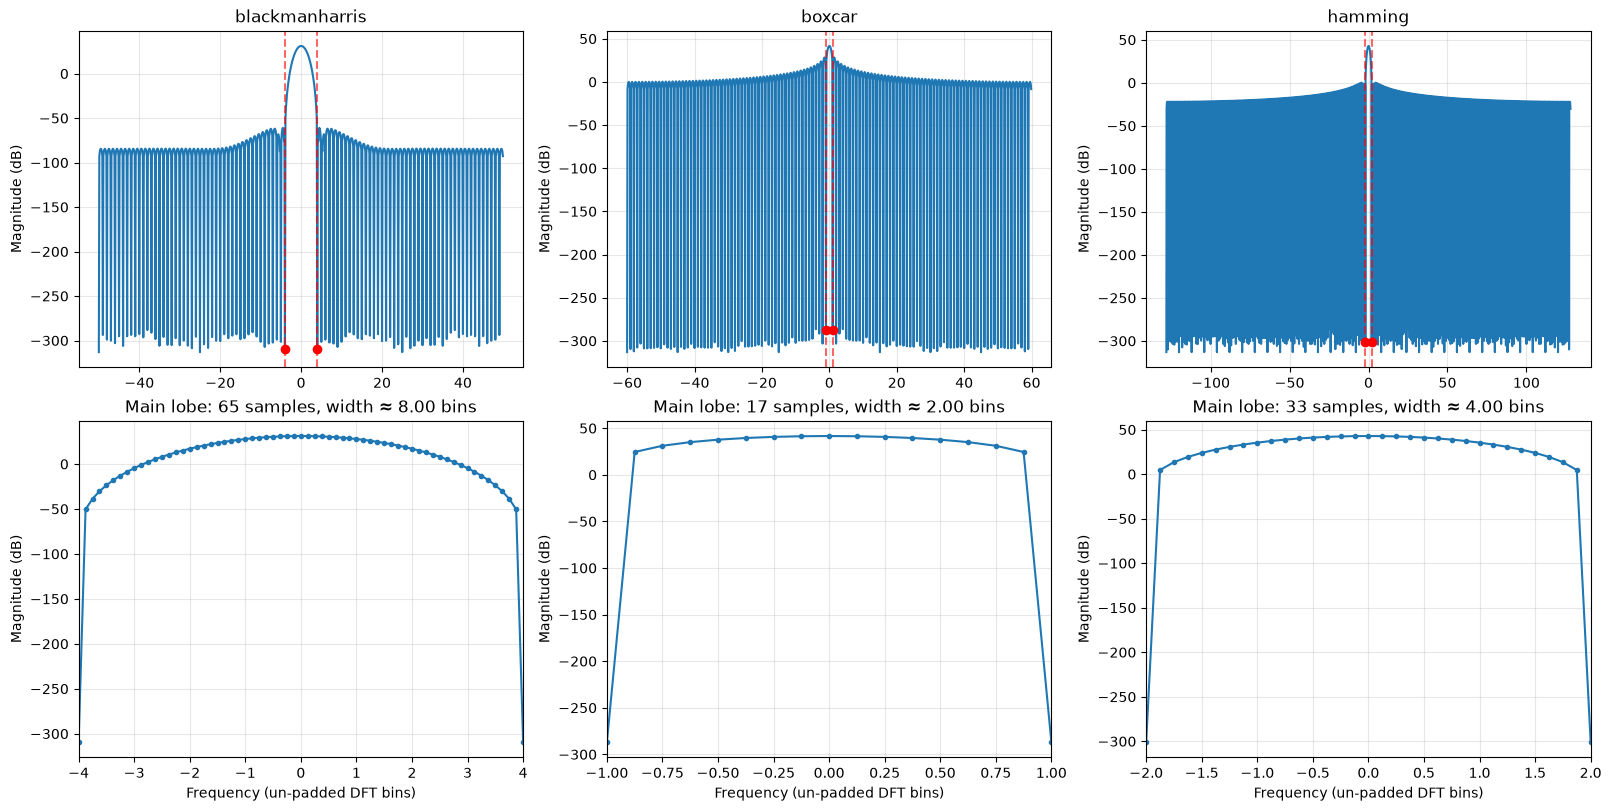

In [10]:
# E4 - 1.2: Call extract_main_lobe() for the 3 test cases, plot the magnitude spectrum of each window
#            with the main-lobe boundaries marked. Compute and report the normalized main-lobe width.

### Your code here

test_cases = [
    ("blackmanharris", 100, 800, 65, 8),
    ("boxcar", 120, 960, 17, 2),
    ("hamming", 256, 2048, 33, 4),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)

for col, (window, M, N, expected_samples, theoretical_width) in enumerate(test_cases):
    main_lobe = extract_main_lobe(window, M, N)
    assert len(main_lobe) == expected_samples, (
        f"{window}: expected {expected_samples} samples, got {len(main_lobe)}"
    )

    # Compute the full, zero-phase-windowed spectrum.
    w = get_window(window, M)
    hM1 = (M + 1) // 2
    hM2 = M // 2

    fftbuffer = np.zeros(N)
    fftbuffer[:hM1] = w[hM2:]
    fftbuffer[N - hM2:] = w[:hM2]

    mW = 20 * np.log10(np.abs(fftshift(fft(fftbuffer))) + eps)

    center_idx = N // 2
    half_width = (len(main_lobe) - 1) // 2
    left_idx = center_idx - half_width
    right_idx = center_idx + half_width

    # Use un-padded DFT bins for the horizontal axis.
    zero_padding_factor = N / M
    x = (np.arange(N) - N // 2) / zero_padding_factor
    x_main = x[left_idx:right_idx + 1]
    normalized_width = x[right_idx] - x[left_idx]

    # Top row: full spectrum and main-lobe boundary markers.
    axes[0, col].plot(x, mW)
    axes[0, col].scatter(
        [x[left_idx], x[right_idx]],
        [mW[left_idx], mW[right_idx]],
        color="red",
        zorder=3,
    )
    axes[0, col].axvline(x[left_idx], color="red", linestyle="--", alpha=0.6)
    axes[0, col].axvline(x[right_idx], color="red", linestyle="--", alpha=0.6)
    axes[0, col].set_title(window)
    axes[0, col].set_ylabel("Magnitude (dB)")
    axes[0, col].grid(True, alpha=0.3)

    # Bottom row: cropped main lobe only.
    axes[1, col].plot(x_main, main_lobe, marker="o", markersize=3)
    axes[1, col].set_xlim(x[left_idx], x[right_idx])
    axes[1, col].set_xlabel("Frequency (un-padded DFT bins)")
    axes[1, col].set_ylabel("Magnitude (dB)")
    axes[1, col].set_title(
        f"Main lobe: {len(main_lobe)} samples, width ≈ {normalized_width:.2f} bins"
    )
    axes[1, col].grid(True, alpha=0.3)

    print(
        f"{window}: {len(main_lobe)} samples; normalized width "
        f"= {normalized_width:.2f} bins (theoretical: {theoretical_width})"
    )

plt.show()


**E4 - 1.3: Conceptual questions (answer here)**

1. From your plots, report the normalized main-lobe width (in samples) for each of the three window types. How do they compare to the theoretical values (`boxcar` = 2, `hamming` = 4, `blackmanharris` = 8 bins in normalized frequency)?

    The measured main-lobe sample counts are 65 for `Blackman–Harris`, 17 for `boxcar`, and 33 for `Hamming`. The zero-padding factor is `N/M = 8` in each test, so dividing those counts by 8 gives normalized widths of 8.125, 2.125, and 4.125 bins, respectively. These are close to the theoretical widths: 8, 2, and 4 bins. 
    
    The extra 0.125 comes from counting both endpoint samples: the distance between the boundary bins is one sample interval less, giving exactly 8, 2, and 4 bins.

2. The description says that changing `M` does not affect the main-lobe width in samples. Verify this: run `extract_main_lobe('hamming', M=128, N=1024)` and `extract_main_lobe('hamming', M=256, N=2048)`. Are the output lengths the same? Explain why.

    In both cases, N/M = 8. Increasing M and N by the same factor makes the FFT-bin spacing finer, but preserves the main-lobe width in bins after accounting for zero padding.

3. What is the tradeoff between main-lobe width and side-lobe attenuation? Given this tradeoff, which window would you choose for analysing a signal with two closely spaced frequency components, and which for a signal where one component is much weaker than another?

    The tradeoff is that windows with especially low side lobes tend to have wider main lobes: they reduce leakage, but make nearby components harder to distinguish.

    Narrow main lobe: each component is concentrated over a smaller frequency range. Nearby components are less likely to blend together, so this is useful when their frequencies are close.
    
    Low side lobes: less energy from a strong component leaks into other frequencies. That makes a much weaker component easier to see, provided it’s far enough from the strong one.
    
    For choices: `boxcar` has the narrowest main lobe, so it’s useful for resolving `closely spaced components`. `Blackman–Harris` has much lower side lobes, so it’s useful for finding a `weak component near a stronger one` — provided the two aren’t so close that the wide main lobe merges them. Hamming is a middle ground.

    `In short: main-lobe width affects whether nearby tones blur together; side-lobe height affects whether a strong tone masks a weaker one`



## Part 2 – Measuring reconstruction noise using the STFT model

The function `compute_snr()` should quantify the distortion introduced by STFT analysis followed by synthesis, using the signal-to-noise ratio (SNR) in dB.

**Steps:**
1. Load the audio file using `UF.wavread()`.
2. Run STFT analysis and synthesis via `stft.stftAnal()` and `stft.stftSynth()`.
3. Trim the output to the same length as the input (synthesis may be slightly longer).
4. Compute the noise signal as `noise = input_signal - output_signal`.
5. Calculate two SNR values:
   - **SNR1**: over the full signal length
   - **SNR2**: after discarding the first and last `M` samples (reduces boundary effects)

**Inputs:**
- `input_file` (str): path to a `.wav` file
- `window` (str): analysis window type
- `M` (int): window length (odd)
- `N` (int): FFT size (power of 2, $N > M$)
- `H` (int): hop size

**Output:** tuple `(SNR1, SNR2)` — both values in dB.


In [43]:
# E4 - 2.1: Complete function compute_snr()

def compute_snr(input_file, window, M, N, H):
    """Measure the amount of distortion introduced during the analysis and synthesis of a signal using the STFT model.

    Args:
        input_file (str): wav file name including the path
        window (str): analysis window type (rectangular, triangular, hanning, hamming, blackman, or blackmanharris)
        M (int): analysis window length (odd positive integer)
        N (int): fft size (power of two, > M)
        H (int): hop size for the stft computation

    Result:
        tuple with the signal to noise ratio over the whole sound and of the sound without the begining and end.
    """
    ### your code here
    _, x = UF.wavread(input_file)
    w = get_window(window, M)
    # mX, pX = stft.stftAnal(x, w, N, H)
    # y = stft.stftSynth(mX, pX, M, H)
    y=stft.stft(x, w, N, H)
    y2= y[M+1:-M]
    x2= x[M+1:-M]
    energy_x = np.sum(abs(x)**2)
    energy_x2 = np.sum(abs(x2)**2)

    noise1 = x-y
    noise2 = x2-y2
    energy_noise1 = np.sum(abs(noise1)**2)
    energy_noise2 = np.sum(abs(noise2)**2)

    SNR1 = 10*np.log10(energy_x/energy_noise1)
    SNR2 = 10*np.log10(energy_x2/energy_noise2)
    return SNR1, SNR2



Test cases for `compute_snr()`:

**Test case 1:** `piano.wav`, `window = 'blackman'`, `M = 513`, `N = 2048`, `H = 128`
→ expected: `(SNR1 ≈ 67.6 dB, SNR2 ≈ 86.4 dB)`

**Test case 2:** `sax-phrase-short.wav`, `window = 'hamming'`, `M = 512`, `N = 1024`, `H = 64`
→ expected: `(SNR1 ≈ 89.5 dB, SNR2 ≈ 306.2 dB)`

**Test case 3:** `rain.wav`, `window = 'hann'`, `M = 1024`, `N = 2048`, `H = 128`
→ expected: `(SNR1 ≈ 74.6 dB, SNR2 ≈ 304.3 dB)`

> Note: SNR values may vary slightly across machines due to floating-point differences.


In [44]:
# E4 - 2.2: Call the function compute_snr() for the 3 test cases mentioned, explain the results

### Your code here
test_cases = [
    ("piano.wav", "blackman", 513, 2048, 128),
    ("sax-phrase-short.wav", 'hamming', 512, 1024, 64),
    ("rain.wav", "han", 1024, 2048, 128)
]

for input, w, M, N, H in test_cases:
    y = compute_snr(f"../sounds/{input}", w, M, N, H)
    print(f"Results for {input}: {y}")


Results for piano.wav: (67.54018457559313, 86.35716321925507)
Results for sax-phrase-short.wav: (89.51050629592375, 307.07827286066174)
Results for rain.wav: (74.63147527768999, 306.7400066597583)


**E4 - 2.3: Conceptual questions (answer here)**

1. For each test case, SNR2 is significantly higher than SNR1. What do the first and last `M` samples represent in the STFT reconstruction, and why are they noisier than the interior?

    The first and last M samples are the regions near the signal boundaries. STFT analysis pads the signal with zeros outside its actual beginning and end, so these edge samples are reconstructed using less complete overlap between frames than interior samples. This can make the reconstruction error larger at the edges. SNR2 excludes those regions, so it is usually higher than SNR1.

2. Compare SNR1 values across the three test cases (piano, sax, rain). The values differ substantially. What properties of the signal or the analysis parameters could explain these differences?

    SNR1 depends on both the reconstruction error and the signal’s energy. The window and hop size affect how frames overlap and how well the signal is reconstructed; the signal’s content and energy near its boundaries also affect the result. 
    
    So a lower SNR for piano does not necessarily mean that the piano signal is intrinsically worse—it means the reconstruction error is larger relative to its signal energy for that test case.

3. If you increase the hop size `H` while keeping `M` and `N` fixed, would you expect the SNR to increase or decrease? Why? Verify with one example.

    Increasing H means frames are farther apart, so they overlap less. I would generally expect the SNR to decrease because there are fewer overlapping frames contributing to each sample, which can make reconstruction less accurate. The exact change depends on the window and hop size; certain combinations can overlap-add especially well.

    As expected, the SNR ratio decreased as the H increased



In [45]:
for H_test in [128, 256]:
    print(
        f"H={H_test}: "
        f"SNR1, SNR2 = {compute_snr("../sounds/piano.wav", 'blackman', 513, 2048, H_test)}"
    )

H=128: SNR1, SNR2 = (67.54018457559313, 86.35716321925507)
H=256: SNR1, SNR2 = (17.49264243867447, 17.49260657950599)


## Part 3 – Computing band-wise energy envelopes

The function `compute_eng_env()` should compute energy envelopes for two frequency bands of an audio signal using the STFT.

**Frequency bands:**
- **Low band:** $0 < f < 3000$ Hz (excluding boundaries)
- **High band:** $3000 < f < 10000$ Hz (excluding boundaries)

**Steps:**
1. Load the audio file and run `stftAnal()` to get the magnitude spectra in dB for all frames.
2. Convert magnitude spectra from dB back to linear scale: $|X| = 10^{m_X/20}$.
3. For each frame, use `np.where()` to find bin indices within each band. The bin frequency is $f_k = k \cdot f_s / N$.
4. Compute per-frame band energy as the sum of squared linear magnitudes across the band's bins.
5. Convert each energy value to dB: $E_{\mathrm{dB}} = 10\log_{10}(E)$.

**Inputs:**
- `input_file` (str): path to a mono `.wav` file (44100 Hz)
- `window` (str): analysis window type
- `M` (int): window length (odd, power-of-2 convenient)
- `N` (int): FFT size (power of 2, $N > M$)
- `H` (int): hop size

**Output:** 2D np.array with shape `(num_frames, 2)` — column 0 is the low-band envelope, column 1 is the high-band envelope, both in dB.


In [57]:
# E4 - 3.1: Complete function compute_eng_env()

def compute_eng_env(input_file, window, M, N, H):
    """Compute band-wise energy envelopes of a given audio signal using the STFT.

    Args:
        input_file (string): input sound file (monophonic with sampling rate of 44100)
        window (string): analysis window type (choice of rectangular, triangular, hanning,
                hamming, blackman, blackmanharris)
        M (integer): analysis window size (odd positive integer)
        N (integer): FFT size (power of 2, such that N > M)
        H (integer): hop size for the stft computation

    Result:
        np.array: magnitude spectra of sound (2D array)
        np.array: 2D numpy array with energy envelope of band 0 < f < 3000 Hz (in dB) in first column, [:,0]
        np.array: energy envelope of band 3000 < f < 10000 Hz (in dB) in second column [:,1]
    """

    ### your code here
    fs, x = UF.wavread(input_file)
    w = get_window(window, M)
    mX, _ = stft.stftAnal(x, w, N, H)
    mX_converted = 10**(mX/20)

    freqs = np.arange(mX.shape[1])*fs/N

    low_bins = np.where((freqs>0) & (freqs<3000))[0]
    high_bins = np.where((freqs>3000) & (freqs<10000))[0]
    print('Number of k bins for low frequency band:',len(low_bins))
    print('Number of k bins for high frequency band:',len(high_bins))

    low_energy = np.sum(mX_converted[:, low_bins]**2, axis=1)
    high_energy = np.sum(mX_converted[:, high_bins]**2, axis=1)

    eps = np.finfo(float).eps

    return mX, 10*np.log10(low_energy+eps), 10*np.log10(high_energy+eps)
    


Test cases for `compute_eng_env()`:

**Test case 1:** `piano.wav`, `window = 'blackman'`, `M = 513`, `N = 1024`, `H = 128`
→ low band: bins 1–69 (69 bins); high band: bins 70–232 (163 bins)

**Test case 2:** `piano.wav`, `window = 'blackman'`, `M = 2047`, `N = 4096`, `H = 128`
→ low band: bins 1–278 (278 bins); high band: bins 279–928 (650 bins)

**Test case 3:** `sax-phrase-short.wav`, `window = 'hamming'`, `M = 513`, `N = 2048`, `H = 256`
→ low band: bins 1–139 (139 bins); high band: bins 140–464 (325 bins)

Plot both energy envelopes together with the signal's spectrogram (use `plt.pcolormesh` or reuse the code from `lectures/4-STFT/plots-code/spectrogram.py`). Use the same time-axis range for both. You should see sharp attacks and decays for the piano notes in test case 1 — compare with test case 2 (larger window) to observe the effect of window length on temporal resolution.


Number of k bins for low frequency band: 69
Number of k bins for high frequency band: 163


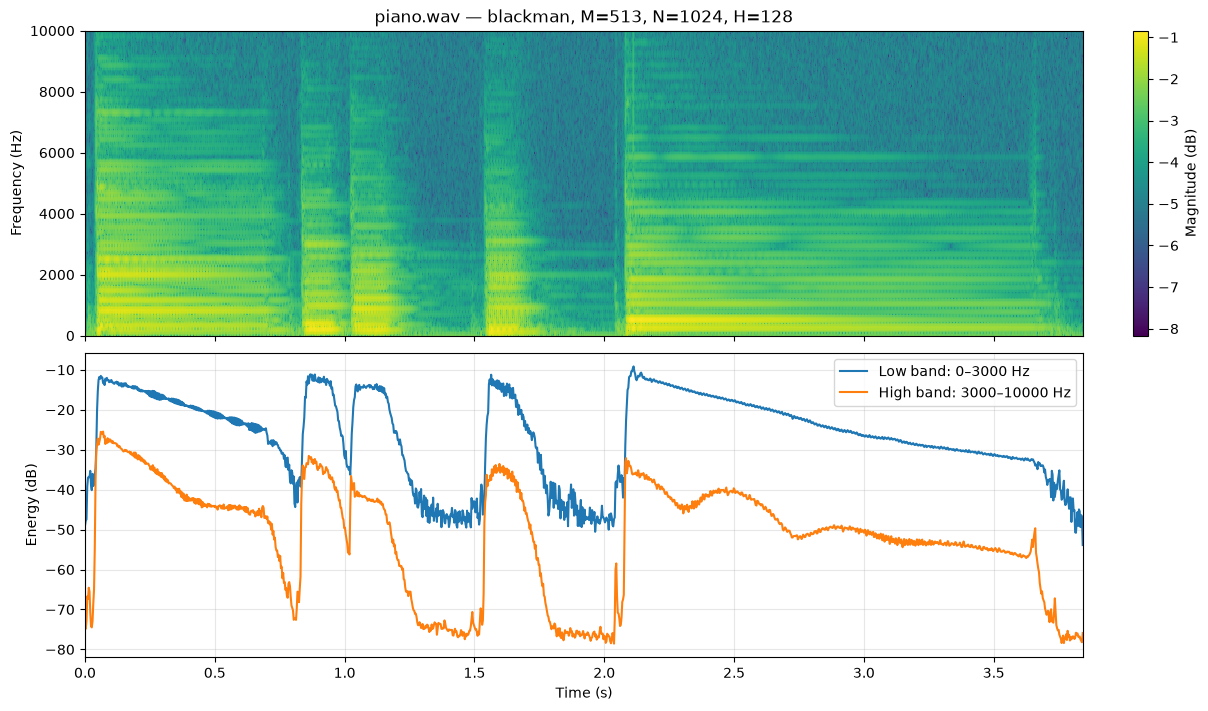

Number of k bins for low frequency band: 278
Number of k bins for high frequency band: 650


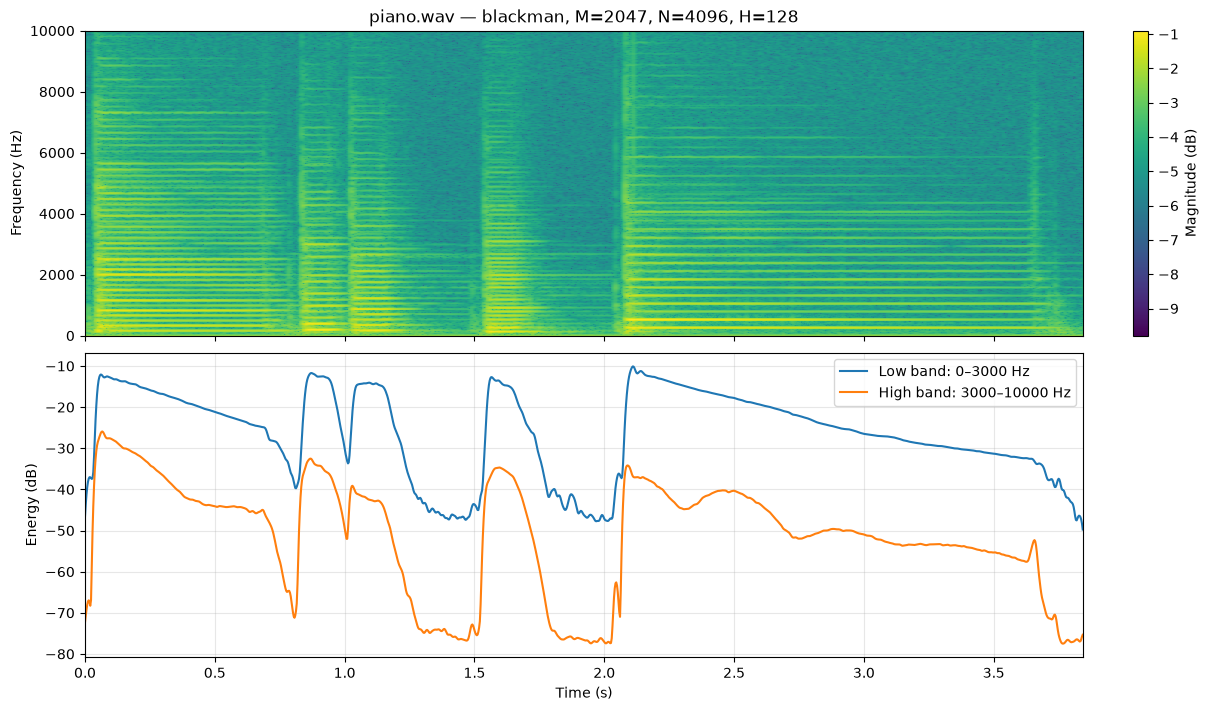

Number of k bins for low frequency band: 139
Number of k bins for high frequency band: 325


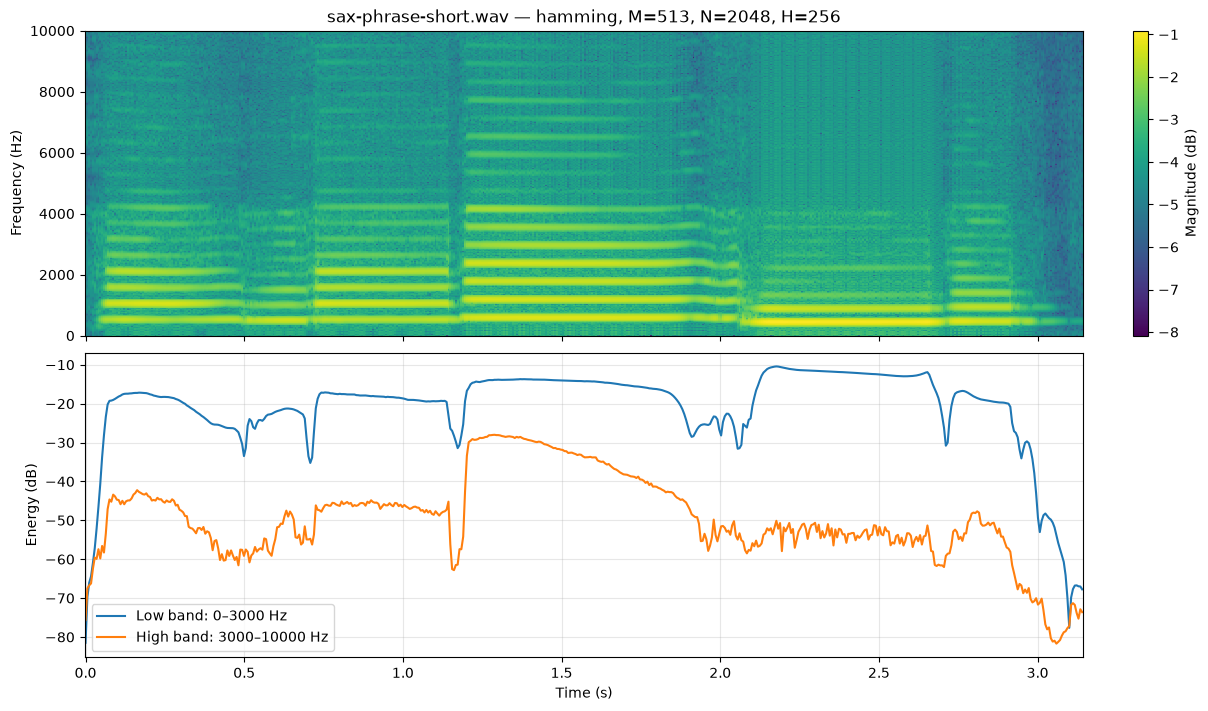

In [58]:
# E4 - 3.2: Call compute_eng_env() for the 3 test cases and plot both energy envelopes
#            together with the spectrogram. Use the same time axis for all subplots.

### Your code here

test_cases = [
    ("piano.wav", "blackman", 513, 1024, 128),
    ("piano.wav", "blackman", 2047, 4096, 128),
    ("sax-phrase-short.wav", "hamming", 513, 2048, 256),
]

for filename, window, M, N, H in test_cases:
    input_file = f"../sounds/{filename}"

    # Compute spectra and band-energy envelopes.
    mX, energy_low, energy_high = compute_eng_env(input_file, window, M, N, H)
    eng_env = np.column_stack((energy_low, energy_high))
    fs, _ = UF.wavread(input_file)

    # Time and frequency coordinates for the STFT frames and bins.
    times = np.arange(mX.shape[0]) * H / fs
    freqs = np.arange(mX.shape[1]) * fs / N

    fig, axes = plt.subplots(
        2, 1, figsize=(12, 7), sharex=True, constrained_layout=True
    )

    # Spectrogram (show 0-10 kHz, the range used for the two bands).
    image = axes[0].pcolormesh(
        times, freqs, mX.T, shading="auto"
    )
    axes[0].set_ylim(0, 10000)
    axes[0].set_ylabel("Frequency (Hz)")
    axes[0].set_title(f"{filename} — {window}, M={M}, N={N}, H={H}")
    fig.colorbar(image, ax=axes[0], label="Magnitude (dB)")

    # Low- and high-band energy envelopes.
    axes[1].plot(times, eng_env[:, 0], label="Low band: 0–3000 Hz")
    axes[1].plot(times, eng_env[:, 1], label="High band: 3000–10000 Hz")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Energy (dB)")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.show()



**E4 - 3.3: Conceptual questions (answer here)**

1. From your spectrogram plot for test case 1 (`piano.wav`, `M=513`), visually identify a piano note onset and describe how the low-band and high-band envelopes behave at that moment. Which band reacts more sharply?

    In the spectrogram, a piano note onset is visible as a sudden vertical increase in energy at about [0.0, 0.8, 1.0, 1.5, 2.1]. Both band envelopes rise at the onset. The high-band envelope often reacts more sharply, because a note’s attack contains brief, broadband high-frequency energy, while the low band is more strongly associated with the fundamental and lower harmonics.

2. Compare envelopes from test case 1 (`M=513`) and test case 2 (`M=2047`) for the same file. How does increasing the window size affect the temporal sharpness of the note attacks in the envelope? Explain the underlying tradeoff.

    With M=513, the energy envelope follows piano attacks more sharply. Increasing the window to M=2047 makes the envelope smoother and the attacks more spread out in time, because each STFT frame summarizes a longer section of audio. The tradeoff is time versus frequency resolution: a longer window improves frequency resolution but reduces temporal precision, blurring rapid changes such as note attacks.

3. Why is the DC bin (bin 0) excluded from the energy calculation? What kind of signal component does it represent, and what would happen to the energy values if you included it?

    The DC bin is the zero-frequency component; for a frame, it represents its average value (local mean), such as a signal offset rather than an oscillating tone. It is excluded so that this constant component does not contribute to the band-energy measurement. If the audio has a nonzero offset, including DC would add energy to the low-band envelope and could make it appear higher than the energy from the actual low-frequency sound.


## Part 4 – Computing an onset detection function

The function `compute_odf()` should compute a half-wave-rectified energy-based ODF for two frequency bands, using the same low/high band definitions as Part 3.

**Steps:**
1. Compute the band-wise energy envelopes (in dB) exactly as in Part 3.
2. Compute the frame-to-frame energy difference: $O(l) = E(l) - E(l-1)$ for $l \geq 1$, with $O(0) = 0$.
3. Apply half-wave rectification: set all negative values to 0.

**Inputs:**
- `input_file` (str): path to a mono `.wav` file (44100 Hz)
- `window` (str): analysis window type
- `M` (int): window length (odd)
- `N` (int): FFT size (power of 2, $N > M$)
- `H` (int): hop size

**Output:** 2D np.array with shape `(num_frames, 2)` — column 0 is the ODF for the low band, column 1 for the high band.


In [59]:
# E4 4.1: Complete function compute_odf()

def compute_odf(input_file, window, M, N, H):
    """Compute a simple onset detection function (ODF) using the STFT.

    Args:
        input_file (str): input sound file (monophonic with sampling rate of 44100)
        window (str): analysis window type (rectangular, triangular, hanning, hamming, blackman, or blackmanharris)
        M (int): analysis window size (odd integer value)
        N (int): fft size (power of two, bigger or equal than than M)
        H (int): hop size for the STFT computation

    Result:
            np.array: magnitude spectra of sound (2D array)
            np.array: D numpy array with ODF computed in band 0 < f < 3000 Hz (in dB) in first column, [:,0]
            np.array: ODF computed of band 3000 < f < 10000 Hz (in dB) in second column [:,1]
    """

    ### your code here
    mX, energy_low, energy_high = compute_eng_env(input_file, window, M, N, H)

    odf_low = np.maximum(np.diff(energy_low, prepend=energy_low[0]), 0)
    odf_high = np.maximum(np.diff(energy_high, prepend=energy_high[0]), 0)

    return mX, np.column_stack((odf_low, odf_high))


Test cases for `compute_odf()` (same parameters as Part 3):

**Test case 1:** `piano.wav`, `window = 'blackman'`, `M = 513`, `N = 1024`, `H = 128`

**Test case 2:** `piano.wav`, `window = 'blackman'`, `M = 2047`, `N = 4096`, `H = 128`

**Test case 3:** `sax-phrase-short.wav`, `window = 'hamming'`, `M = 513`, `N = 2048`, `H = 256`

Plot each ODF together with the spectrogram of the corresponding signal (same time axis). For test case 1, you should see **5 clear peaks above 10 dB** in the high-band ODF, corresponding to the onsets of the piano notes.


Number of k bins for low frequency band: 69
Number of k bins for high frequency band: 163


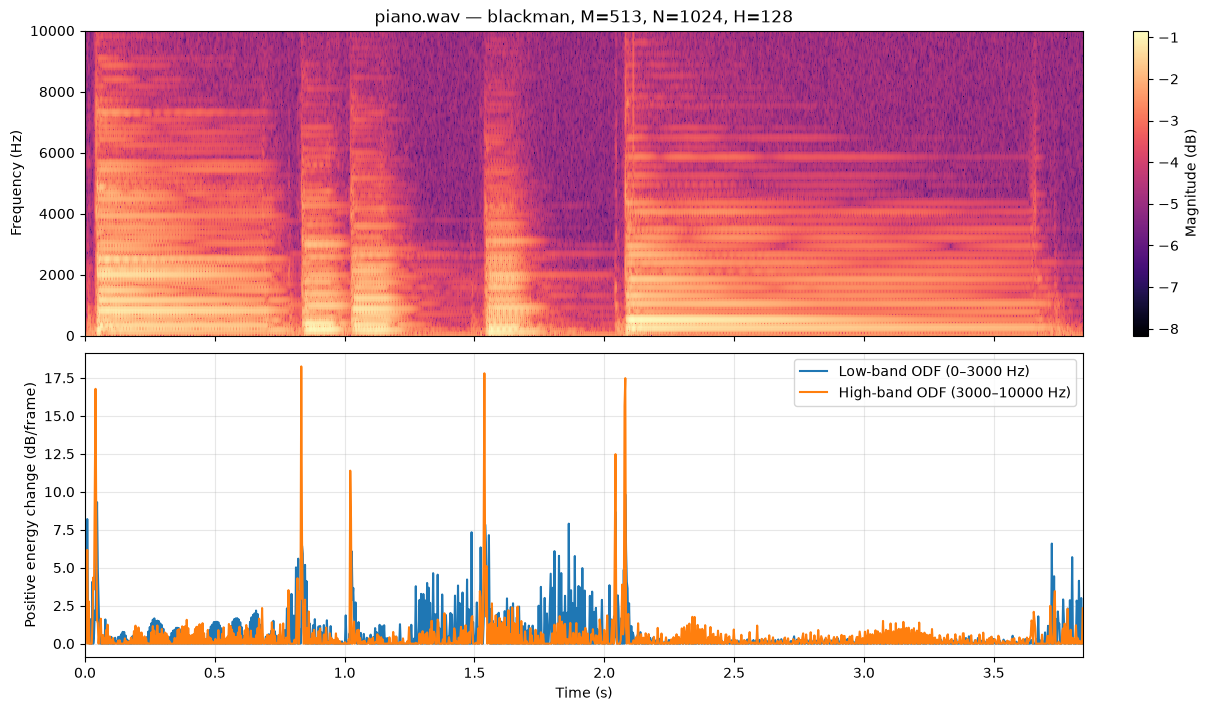

High-band ODF peaks above 10 dB: 8
Number of k bins for low frequency band: 278
Number of k bins for high frequency band: 650


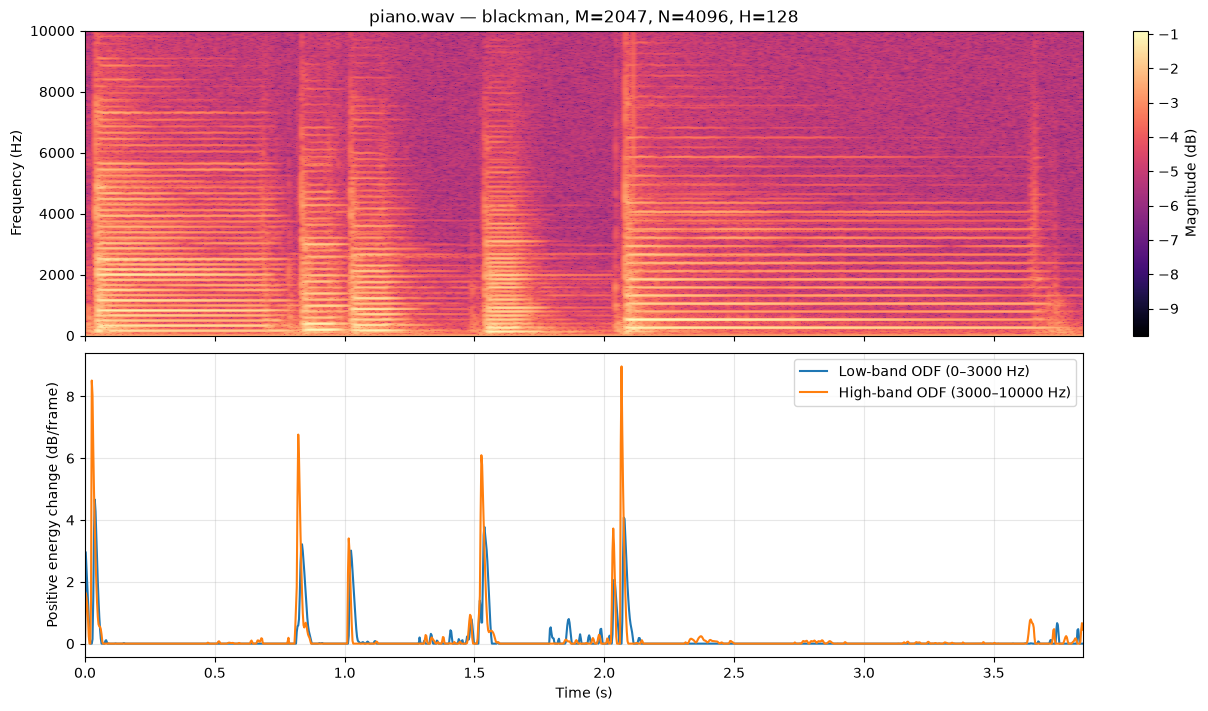

Number of k bins for low frequency band: 139
Number of k bins for high frequency band: 325


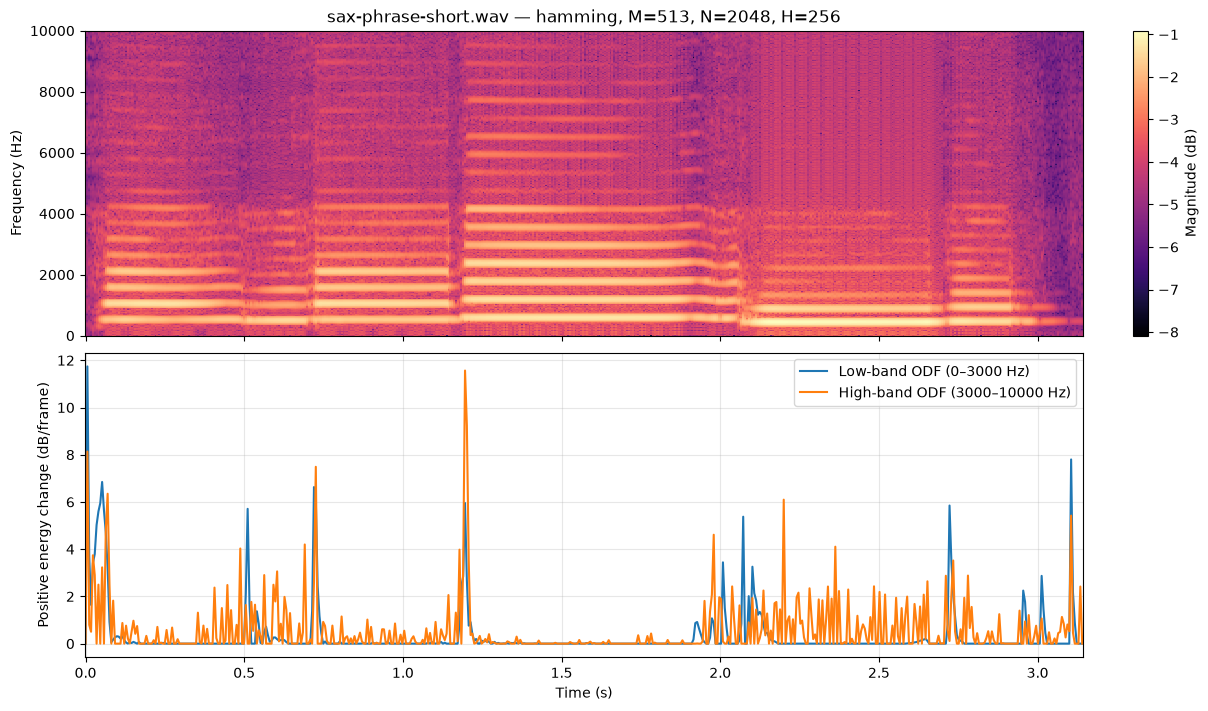

In [60]:
# E4 - 4.2: Call compute_odf() for the 3 test cases and plot the ODF functions together with
#            the spectrogram of the signal. Use the same time axis for both.

### Your code here
test_cases = [
    ("piano.wav", "blackman", 513, 1024, 128),
    ("piano.wav", "blackman", 2047, 4096, 128),
    ("sax-phrase-short.wav", "hamming", 513, 2048, 256),
]

for filename, window, M, N, H in test_cases:
    input_file = f"../sounds/{filename}"

    # Load the signal and compute its spectrogram.
    fs, _ = UF.wavread(input_file)

    # Compute low- and high-band onset detection functions.
    mX, odf = compute_odf(input_file, window, M, N, H)

    # Frame times and one-sided FFT-bin frequencies.
    times = np.arange(mX.shape[0]) * H / fs
    freqs = np.arange(mX.shape[1]) * fs / N

    fig, axes = plt.subplots(
        2, 1, figsize=(12, 7), sharex=True, constrained_layout=True
    )

    # Spectrogram, limited to the frequency range used by the ODF bands.
    image = axes[0].pcolormesh(
        times, freqs, mX.T, shading="auto", cmap="magma"
    )
    axes[0].set_ylim(0, 10000)
    axes[0].set_ylabel("Frequency (Hz)")
    axes[0].set_title(f"{filename} — {window}, M={M}, N={N}, H={H}")
    fig.colorbar(image, ax=axes[0], label="Magnitude (dB)")

    # ODFs use the same frame times as the spectrogram.
    axes[1].plot(times, odf[:, 0], label="Low-band ODF (0–3000 Hz)")
    axes[1].plot(times, odf[:, 1], label="High-band ODF (3000–10000 Hz)")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Positive energy change (dB/frame)")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.show()

    if filename == "piano.wav" and M == 513:
        print("High-band ODF peaks above 10 dB:", np.sum(odf[:, 1] > 10))



**E4 - 4.3: Conceptual questions (answer here)**

1. For test case 1 (`piano.wav`, `M=513`), count the peaks above 10 dB in the high-band ODF. Do they correspond to audible note onsets? Compare the peak locations in the low-band vs. high-band ODFs. Which band is more reliable for detecting piano note onsets, and why?

    In the high-band ODF, I can see six prominent peaks above 10 dB. They line up with sudden changes in the spectrogram and are likely note onsets except the one at 2.05s which is likely the echo of hitting the keys in the piano. The low-band ODF also rises around several of these times, but it has more smaller fluctuations. 
    
    In this plot, the `high-band ODF looks more reliable for identifying the clear attacks` because its onset peaks stand out more strongly from its baseline. The exact count and times are approximate from the plot.

2. Compare the ODFs from test case 1 (`M=513`) and test case 2 (`M=2047`). How does window size affect the sharpness and height of the ODF peaks? Which would be easier to threshold for onset detection?

    With M=513, the ODF peaks are taller and more temporally distinct, but there are also more small fluctuations. With M=2047, the ODF is smoother and has fewer fluctuations, but the onset peaks are lower (mostly below 10 dB) and less sharply defined. A longer window averages over more time: it improves frequency detail but blurs rapid timing changes. For these plots, M=513 is easier to threshold using a 10 dB threshold, though a threshold still needs to avoid the smaller fluctuations.

3. What is the effect of half-wave rectification on the ODF? Sketch (or plot) the ODF before and after rectification for one test case. What information is discarded, and why is it not needed for onset detection?

    Before rectification, a negative ODF value means the band energy decreased from one frame to the next. Half-wave rectification clips those negative changes to zero, keeping only energy increases that may indicate onsets. The downward changes are discarded because they usually indicate note decay or offset, not a new attack.

4. Could a single fixed dB threshold reliably detect onsets in all three test cases? Examine the ODF values across cases. If not, what alternative strategy would you propose?

    A single fixed threshold is unlikely to work reliably for every case. The ODF peak heights differ with the window size and signal: in the plots, the M=513 piano peaks reach roughly 18 dB, while the M=2047 piano peaks are below 10 dB. A 10 dB threshold could therefore miss onsets in the second case.

    A better approach is peak-picking with an adaptive threshold, for example by comparing the ODF to a local baseline, and applying a minimum peak prominence and minimum time between detections.


Number of k bins for low frequency band: 69
Number of k bins for high frequency band: 163


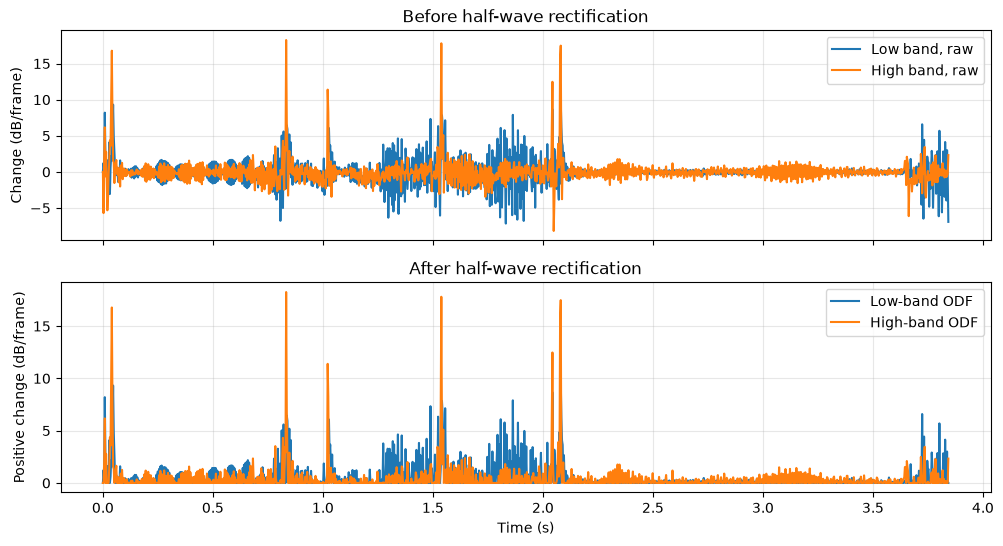

In [61]:
input_file = "../sounds/piano.wav"
window, M, N, H = "blackman", 513, 1024, 128

_, energy_low, energy_high = compute_eng_env(input_file, window, M, N, H)

# Raw frame-to-frame changes, before half-wave rectification.
raw_low = np.diff(energy_low, prepend=energy_low[0])
raw_high = np.diff(energy_high, prepend=energy_high[0])

# Rectified ODF: negative changes become zero.
rectified_low = np.maximum(raw_low, 0)
rectified_high = np.maximum(raw_high, 0)

fs, _ = UF.wavread(input_file)
times = np.arange(len(raw_low)) * H / fs

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(times, raw_low, label="Low band, raw")
axes[0].plot(times, raw_high, label="High band, raw")
axes[0].set_ylabel("Change (dB/frame)")
axes[0].set_title("Before half-wave rectification")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(times, rectified_low, label="Low-band ODF")
axes[1].plot(times, rectified_high, label="High-band ODF")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Positive change (dB/frame)")
axes[1].set_title("After half-wave rectification")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.show()